# Previsione prezzo auto usate (Regression) — CarPrice_Assignment.csv

Obiettivo: **predire il prezzo (`price`)** di un'auto usando caratteristiche tecniche e categorie (marca, tipo carrozzeria, carburante, ecc.).

Checklist:
1. **EDA**: visualizzazione dati, istogrammi, scatter matrix  
2. **Pre-processing**: scaling / trasformazioni / selezione feature  
3. **Training**: split training/validation (e test) + scelta modelli + iperparametri  
4. **Validazione**: confronto modelli/iperparametri + metriche  



In [2]:
# Importazione librerie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import scatter_matrix

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

plt.style.use('default')


In [4]:
# Caricamento dataset
df = pd.read_csv('CarPrice_Assignment.csv')
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


### EDA (Exploratory Data Analysis)
- guardiamo distribuzione del **prezzo**
- istogrammi delle variabili numeriche
- scatter matrix su un sottoinsieme di feature per vedere relazioni con `price`
- correlazioni tra numeriche


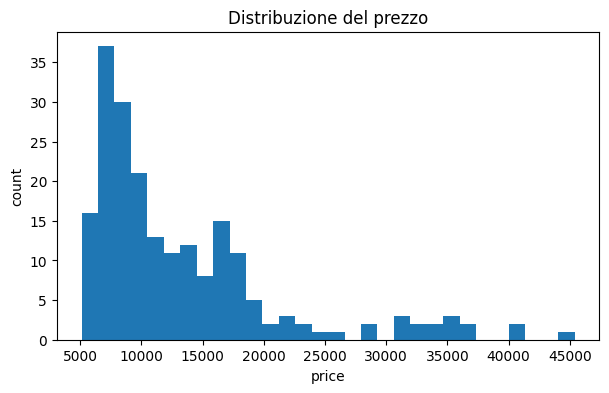

In [5]:
# Istogramma del prezzo
plt.figure(figsize=(7,4))
plt.hist(df['price'], bins=30)
plt.title('Distribuzione del prezzo')
plt.xlabel('price')
plt.ylabel('count')
plt.show()


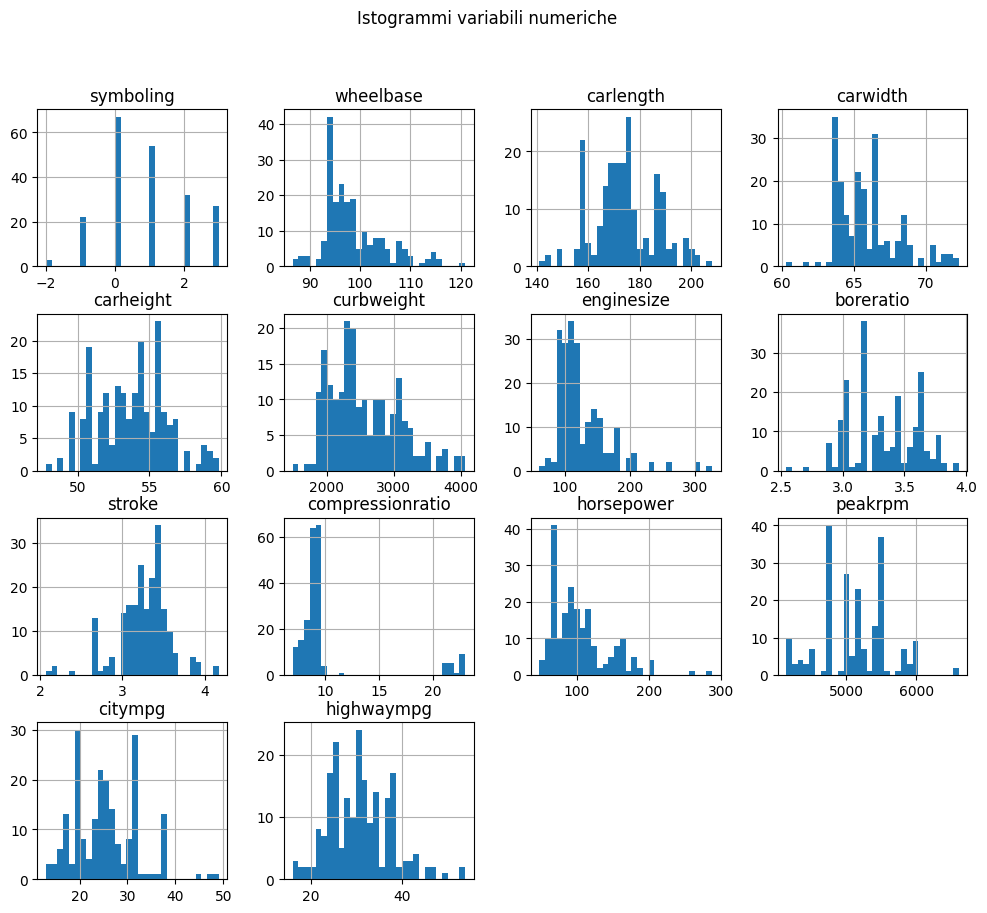

In [6]:
# Istogrammi delle variabili numeriche (escludo car_ID e price solo per pulizia grafico)
num_col_tot= df.select_dtypes(include=[np.number]).columns.tolist()
num_cols_plot = [c for c in num_col_tot if c not in ['car_ID', 'price']]

df[num_cols_plot].hist(bins=30, figsize=(12,10))
plt.suptitle('Istogrammi variabili numeriche')
plt.show()


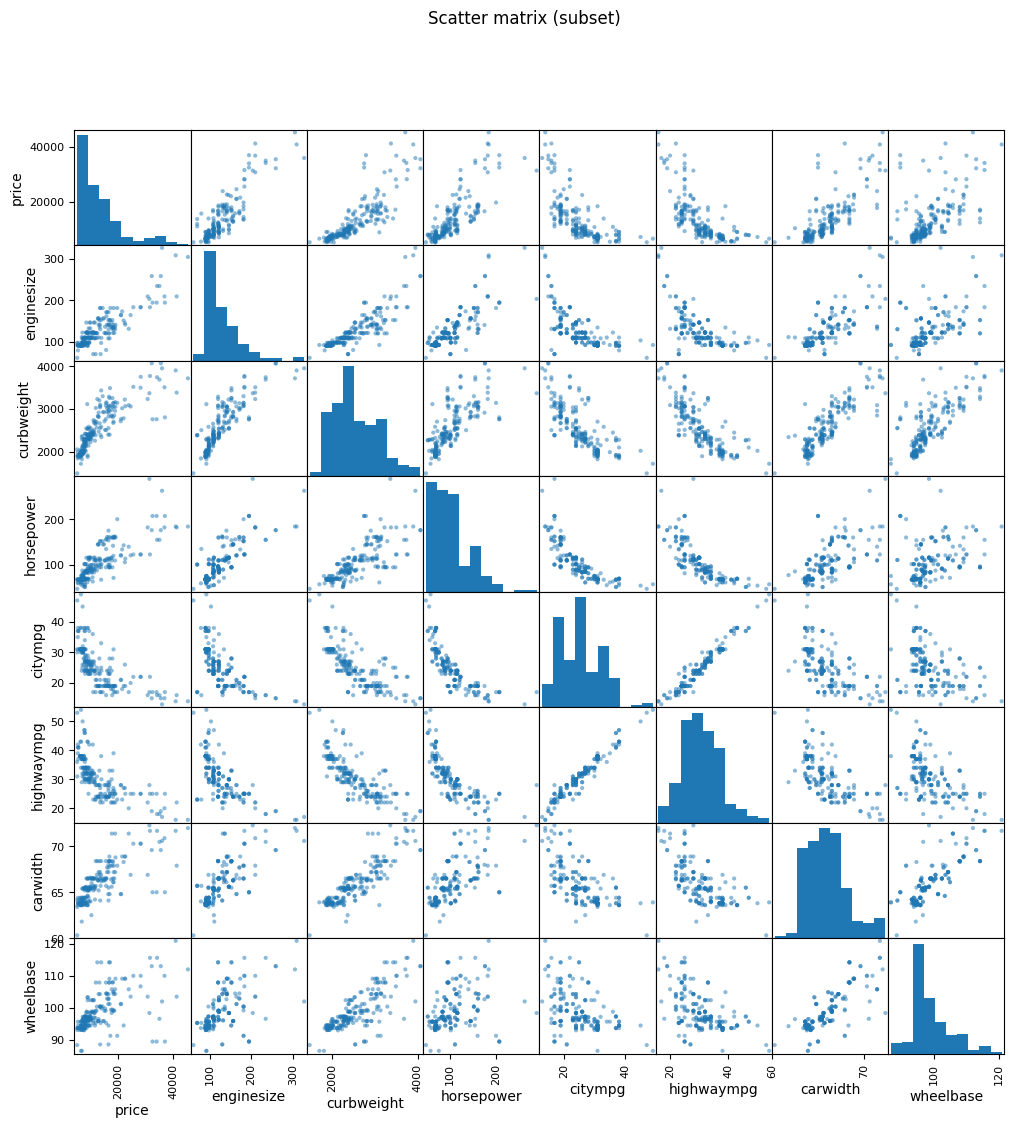

In [7]:
# Scatter matrix (subset)
subset = ['price','enginesize','curbweight','horsepower','citympg','highwaympg','carwidth','wheelbase']
scatter_matrix(df[subset], figsize=(12,12))
plt.suptitle('Scatter matrix (subset)')
plt.show()


In [8]:
# Correlazioni tra numeriche (con price)
corr = df.select_dtypes(include=[np.number]).corr(numeric_only=True)['price'].sort_values(ascending=False)
print('Correlazione con price (numeriche):\n')
print(corr)


Correlazione con price (numeriche):

price               1.000000
enginesize          0.874145
curbweight          0.835305
horsepower          0.808139
carwidth            0.759325
carlength           0.682920
wheelbase           0.577816
boreratio           0.553173
carheight           0.119336
stroke              0.079443
compressionratio    0.067984
symboling          -0.079978
peakrpm            -0.085267
car_ID             -0.109093
citympg            -0.685751
highwaympg         -0.697599
Name: price, dtype: float64


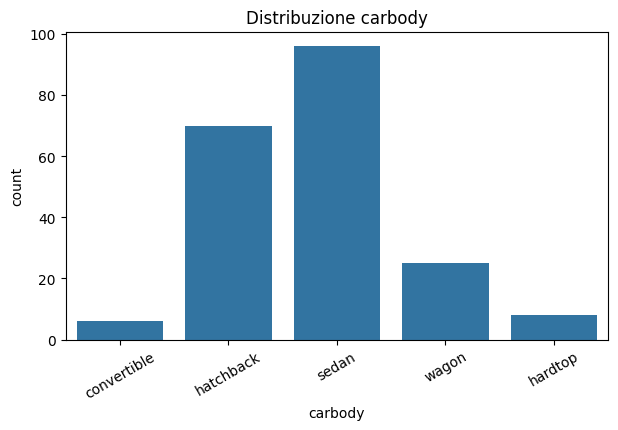

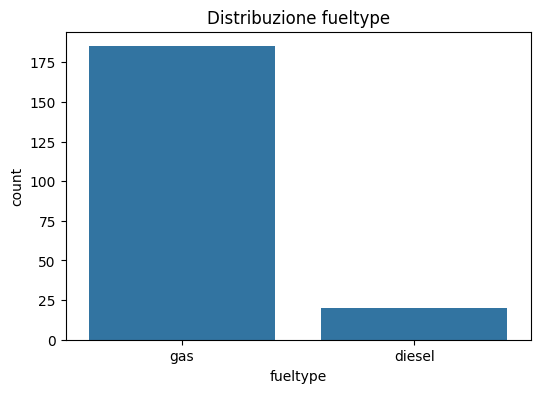

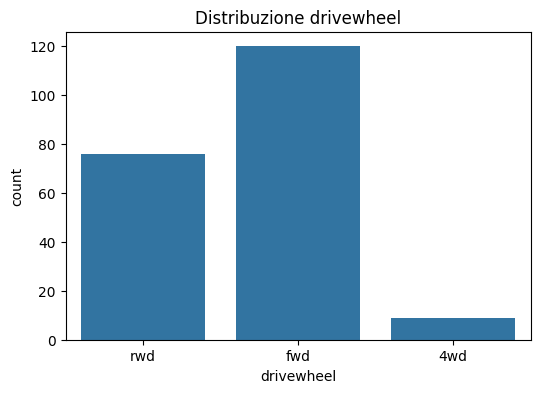

In [9]:
# Distribuzione alcune variabili categoriche
plt.figure(figsize=(7,4))
sns.countplot(x='carbody', data=df)
plt.title('Distribuzione carbody')
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x='fueltype', data=df)
plt.title('Distribuzione fueltype')
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x='drivewheel', data=df)
plt.title('Distribuzione drivewheel')
plt.show()


### Feature Engineering
`CarName` contiene "marca + modello"  
Per non creare troppe categorie diverse, estraiamo solo la **marca**.





In [11]:
# Feature engineering: estrazione brand
df_fe = df.copy()

# brand = prima parola di CarName
df_fe['brand'] = df_fe['CarName'].str.split().str[0].str.lower()

# correzione typo frequenti
df_fe['brand'] = df_fe['brand'].replace({
    'maxda':'mazda',
    'porcshce':'porsche',
    'toyouta':'toyota',
    'vokswagen':'volkswagen',
    'vw':'volkswagen'
})

# ci teniamo CarName SOLO per output finale
df_fe['carname_full'] = df_fe['CarName']

# rimuovo colonne non utili per training
df_fe = df_fe.drop(columns=['car_ID', 'CarName'])

# --- STAMPE UTILI (uniche) ---
print("Numero brand uniche:", df_fe['brand'].nunique())
print("\nTop 10 brand più frequenti:")
print(df_fe['brand'].value_counts().head(10))

print("\nNumero carname_full unici (marca + modello):", df_fe['carname_full'].nunique())
print("\nEsempio di 15 carname_full unici:")
print(df_fe['carname_full'].drop_duplicates().head(15))

df_fe.head()


Numero brand uniche: 22

Top 10 brand più frequenti:
brand
toyota        32
nissan        18
mazda         17
mitsubishi    13
honda         13
subaru        12
volkswagen    12
volvo         11
peugeot       11
dodge          9
Name: count, dtype: int64

Numero carname_full unici (marca + modello): 147

Esempio di 15 carname_full unici:
0           alfa-romero giulia
1          alfa-romero stelvio
2     alfa-romero Quadrifoglio
3                  audi 100 ls
4                   audi 100ls
5                     audi fox
7                    audi 5000
8                    audi 4000
9          audi 5000s (diesel)
10                    bmw 320i
12                      bmw x1
13                      bmw x3
14                      bmw z4
15                      bmw x4
16                      bmw x5
Name: carname_full, dtype: object


,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand,carname_full
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero,alfa-romero giulia
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero,alfa-romero stelvio
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero,alfa-romero Quadrifoglio
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,3.19,3.40,10.0,102,5500,24,30,13950.0,audi,audi 100 ls
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,3.19,3.40,8.0,115,5500,18,22,17450.0,audi,audi 100ls


## Parte 2 Training, Validazione, Consegna


- **Split**: separiamo i dati in train/validation/test.  
  - train: il modello impara  
  - validation: scegliamo modello/iperparametri  
  - test: valutazione finale (dati mai visti)
- **Metriche per regressione**
  - **MAE**: errore assoluto medio (in euro)
  - **RMSE**: radice dell’errore quadratico medio (penalizza errori grandi)
  - **R²**: quota di varianza spiegata (più vicino a 1 = meglio)
- **Ridge Regression**: modello lineare con regolarizzazione L2 (riduce overfitting, stabilizza coefficienti).
- **Random Forest Regressor**: insieme di alberi decisionali; cattura non-linearità, robusto, pochi iperparametri chiave.


In [12]:
# Definizione X (feature) e y (target)
X = df_fe.drop(columns=['price'])
y = df_fe['price']

# split train/val/test (70/15/15)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, random_state=42)

print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

# colonne numeriche e categoriche
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object']).columns.tolist()

print('Categoriche:', cat_cols)
print('Numeriche:', num_cols)


Train: (143, 25) Val: (31, 25) Test: (31, 25)
Categoriche: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand', 'carname_full']
Numeriche: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']


In [13]:
# Preprocessing con ColumnTransformer:
# - numeriche: StandardScaler
# - categoriche: OneHotEncoder
preprocess_ridge = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

# Modello 1: (6.1) Ridge (baseline semplice)
model_ridge = Pipeline(steps=[
    ('preprocess', preprocess_ridge),
    ('model', Ridge(alpha=1.0, random_state=42))
])


In [ ]:
# 6.2 Preprocessing per RandomForest:
# (scaling non necessario per gli alberi => passthrough sulle numeriche)
preprocess_rf = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

# Modello 2: RandomForest (robusto su non-linearità)
model_rf = Pipeline(steps=[
    ('preprocess', preprocess_rf),
    ('model', RandomForestRegressor(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42
    ))
])


In [ ]:
# 7 Funzione di valutazione (su validation o test)
def evaluate_regression(y_true, y_pred, label='MODEL'):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'[{label}] MAE={mae:.2f} | RMSE={rmse:.2f} | R2={r2:.4f}')
    return mae, rmse, r2

# Fit su train e valutazione su validation
model_ridge.fit(X_train, y_train)
pred_val_ridge = model_ridge.predict(X_val)
m_ridge = evaluate_regression(y_val, pred_val_ridge, 'Ridge (val)')

model_rf.fit(X_train, y_train)
pred_val_rf = model_rf.predict(X_val)
m_rf = evaluate_regression(y_val, pred_val_rf, 'RandomForest (val)')

[Ridge (val)] MAE=1426.97 | RMSE=1871.51 | R2=0.9129
[RandomForest (val)] MAE=1449.43 | RMSE=1942.72 | R2=0.9061


In [ ]:
#7 Confronto più stabile: Cross-Validation a 5 fold (sul dataset intero)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'MAE':'neg_mean_absolute_error', 'RMSE':'neg_root_mean_squared_error', 'R2':'r2'}

cv_ridge = cross_validate(model_ridge, X, y, cv=cv, scoring=scoring)
cv_rf = cross_validate(model_rf, X, y, cv=cv, scoring=scoring)

def summarize_cv(cv_res, name):
    mae = -cv_res['test_MAE'].mean()
    rmse = -cv_res['test_RMSE'].mean()
    r2 = cv_res['test_R2'].mean()
    print(f'[{name}] CV(5-fold) -> MAE={mae:.2f} | RMSE={rmse:.2f} | R2={r2:.4f}')
    return mae, rmse, r2

summarize_cv(cv_ridge, 'Ridge')
summarize_cv(cv_rf, 'RandomForest')


[Ridge] CV(5-fold) -> MAE=1670.08 | RMSE=2331.77 | R2=0.9094
[RandomForest] CV(5-fold) -> MAE=1483.71 | RMSE=2089.89 | R2=0.9257


(np.float64(1483.711254587474),
 np.float64(2089.8866906157427),
 np.float64(0.9257146860329787))

### Scelta modello finale
In genere:
- **Ridge** = baseline semplice e spiegabile  
- **Random Forest** = spesso migliora le performance perché cattura relazioni non lineari  
Scegliamo il modello con metriche migliori (soprattutto in cross-validation, più stabile dello split singolo).


[FINAL (test)] MAE=1608.47 | RMSE=2212.73 | R2=0.9451


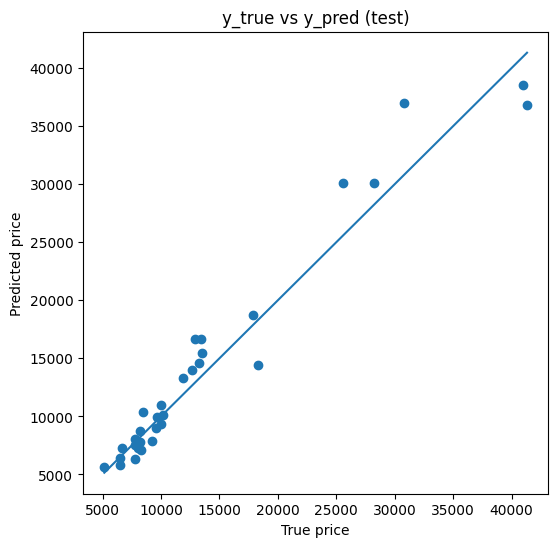

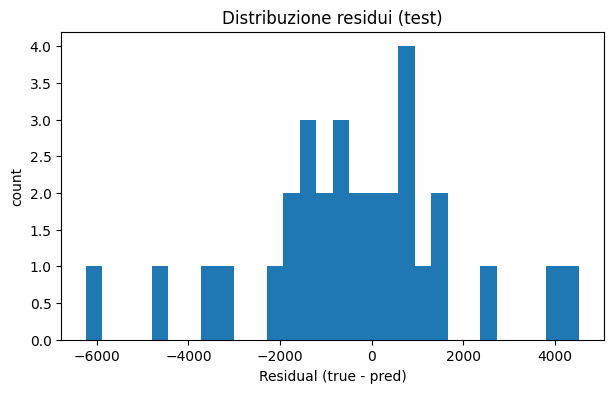

In [ ]:
# 6.1 /6.2 Fit finale su (train + val) e valutazione su test
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

# scegliamo RandomForest come modello finale (di solito migliore in CV)
final_model = model_rf
final_model.fit(X_trainval, y_trainval)

pred_test = final_model.predict(X_test)
evaluate_regression(y_test, pred_test, 'FINAL (test)')

# Grafico: y_true vs y_pred
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred_test)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.title('y_true vs y_pred (test)')
plt.xlabel('True price')
plt.ylabel('Predicted price')
plt.show()

# Residui
residuals = y_test - pred_test
plt.figure(figsize=(7,4))
plt.hist(residuals, bins=30)
plt.title('Distribuzione residui (test)')
plt.xlabel('Residual (true - pred)')
plt.ylabel('count')
plt.show()


In [ ]:
# Consegna: brand + y_true + y_pred + residual + modello usato

predictions_test = pd.DataFrame(index=X_test.index)
predictions_test['carname_full'] = df_fe.loc[X_test.index, 'carname_full']
predictions_test['brand'] = X_test['brand']
predictions_test['y_true'] = y_test
predictions_test['y_pred'] = pred_test
predictions_test['residual'] = predictions_test['y_true'] - predictions_test['y_pred']

predictions_test.head(10)



,carname_full,brand,y_true,y_pred,residual
15,bmw x4,bmw,30760.000,36998.347893,-6238.347893
9,audi 5000s (diesel),audi,17859.167,18718.353885,-859.186885
100,nissan nv200,nissan,9549.000,8964.159791,584.840209
132,saab 99e,saab,11850.000,13315.508343,-1465.508343
68,buick century luxus (sw),buick,28248.000,30084.632406,-1836.632406
95,nissan juke,nissan,7799.000,6363.089762,1435.910238
159,toyota corolla,toyota,7788.000,7535.553583,252.446417
162,toyota mark ii,toyota,9258.000,7889.352658,1368.647342
147,subaru tribeca,subaru,10198.000,10151.853963,46.146037
182,vokswagen rabbit,volkswagen,7775.000,8062.174147,-287.174147
